## Figure 1: Forecast, Method, and Results all in one figure

**Inputs:** `../data/figures/v261102_fig1{a,b,c}.zarr`, written by `d01_prep_data_p01.ipynb`.

**Forecast period:** Oct–Mar (`FC_MONTHS`).

- **(a) Forecast anomaly map.** Gridded Ensemble-mean 2 m temperature anomaly averaged over Oct–Mar (°C), land only. Hatching marks grid cells where fewer than 80% of ensemble members agree on the sign of the anomaly.
  *Sources:* parsed seasonal forecast (`v20261006_parsed_forecast.zarr`, daily, per ensemble member), relative to parsed hindcast climatology (`v20261006_parsed_hindcast.zarr`, daily ensemble mean).
- **(b) Method diagram.** Single region (Kgalagadi, Botswana, `BWA.3`), one month (January) and one age group (65+). 3 panel elements: histograms of daily temperature for the forecast members and for ERA5; the hot-only response curve, with its samples (gamma) and the gamma sample mean MMT; and the cumulative mortality effect (e.g. cdf), with a 5–95% range across samples.
  *Sources:* Gridded 6-month Forecast and ERA5 for 1996–2025 (`POREALLAS_ERA5_URI`), both aggregated to impact regions. Response curves in `POREALLAS_EFFECTS_URI` (`/fixed_beta`, `beta_hotonly`).
- **(c) Response-curve slope map.** The mortality rate slope d(β)/d(T) for age_cohort ages 65+, evaluated at each region's Oct–Mar ensemble-mean forecast temperature and averaged across response-curve gamma samples (rate/°C).
  *Sources:* Full response curve in `POREALLAS_EFFECTS_URI` (`/fixed_beta`, `beta`), IR-aggregated forecast

In [53]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import cartopy.crs as ccrs
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# from dotenv import find_dotenv, load_dotenv
from matplotlib.colors import BivarColormapFromImage, Normalize

from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

<module 'utils.plotting_utils' from '/Users/kellymccusker/LOCAL/ClimateImpactLab/enso_mortality/enso_paper/myfork_test_figs/mccusker_seasonal_2026/utils/plotting_utils.py'>

In [2]:
# load_dotenv(
#     find_dotenv(".env", raise_error_if_not_found=True), override=True
# )

# EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
# IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
# SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

In [162]:
plotsave = True

# Baseline period for Impact
# effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = slice(
    "1996", "2025"
)  # analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]


In [ ]:

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [202]:
# For reference, here are the region options right now:
    # REGION1 = "BWA.3"
    # NAME1 = "Kgalagadi, Botswana"
    # REGION2 = "BRA.19.3634.Rf31287f7cff5d3a1"
    # NAME2 = "Rio de Janeiro, Brazil"

    # REGION3 = "USA.14.608"
    # NAME3 = "Chicago, Illinois, USA"

    # REGION4 = "USA.5.202"
    # NAME4 = "Los Angeles, California, USA"

DBPATH = os.environ["DBPATH"]  # Dropbox path to data in shared folder
FIG1A_PATH = f"{DBPATH}/v261103_fig1a.zarr" # dose response curve, histograms, example location
FIG1loc1_PATH = f"{DBPATH}/v261118_fig1_loc1.zarr" # dose response curve, histograms, example location botswana
FIG1loc2_PATH = f"{DBPATH}/v261118_fig1_loc2.zarr" # dose response curve, histograms, example location rio
FIG1loc3_PATH = f"{DBPATH}/v261119_fig1_loc3.zarr" # dose response curve, histograms, example location. chicago
FIG1loc4_PATH = f"{DBPATH}/v261119_fig1_loc4.zarr" # dose response curve, histograms, example location. los angeles
FIG1loc5_PATH = f"{DBPATH}/v261119_fig1_loc5.zarr" # dose response curve, histograms, example location. melbourne

FIG1B_PATH = f"{DBPATH}/v261106b_fig1b.zarr" # tas anomaly map
FIG1C_PATH = f"{DBPATH}/v261103_fig1c.zarr" # slope at forecast temperature map

FIG2A_PATH = f"{DBPATH}/v261110_fig2a.zarr" # hot-only mortality rate
# FIG2B_PATH = f"{DBPATH}/v261110_fig2b.zarr" # cold-only mortality rate
# FIG2C_PATH = f"{DBPATH}/v261103_fig2c.zarr" # time series of hot-only and cold-only mortality rate
FIG2D_PATH = f"{DBPATH}/v261103_fig2d.zarr" # income quartiles
# FIG2E_PATH = f"{DBPATH}/v261113_fig2e.zarr" # distribution of mortality rates for example location


In [167]:
def _flat(da):
    # Flatten and check xarray
    v = np.asarray(da).ravel()
    return v[np.isfinite(v)]


def load_panel_a(path):
    ds = xr.open_zarr(path, consolidated=True).load()
    return ds["ens_mean"], ds["agreement"], ds.attrs


def load_panel_b(path, pad=3):
    ds = xr.open_zarr(path, consolidated=True).load()
    fc, era5 = ds["fc_tas"], ds["era5_tas"]
    vals = np.concatenate([_flat(fc), _flat(era5)])
    clim = {
        "forecast": fc,
        "era5": era5,
        "n_members": fc.sizes["number"],
        "n_years": np.unique(era5["era5_time"].dt.year).size,
        "xlim": (vals.min() - pad, vals.max() + pad),
    }
    beta = {
        "samples": ds["beta"].values,
        "tas_bin": ds["tas_bin"].values,
        "mmt": ds["mmt"].item(),
    }
    return clim, beta, ds.attrs


def load_panel_c(path, polygons):
    ds = xr.open_zarr(path, consolidated=True).load()
    gdf = analysis_utils.xarray_to_gpd(ds["beta_slope_at_forecast"], polygons)
    return gdf.to_crs(ccrs.Robinson().proj4_init), ds.attrs


def weighted_box_stats(vals, weights, whis=1.5):
    ## Helper for Panel d
    # weights = pop/pop_box
    mask = np.isfinite(vals) & np.isfinite(weights)
    v, w = vals[mask], weights[mask]
    order = np.argsort(v)
    v, w = v[order], w[order]
    # Normalize weights within box
    cdf = (np.cumsum(w) - 0.5 * w) / w.sum()
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, v)
    iqr = q3 - q1
    whislo = v[v >= q1 - whis * iqr].min()
    whishi = v[v <= q3 + whis * iqr].max()
    return {
        "med": med,
        "q1": q1,
        "q3": q3,
        "whislo": whislo,
        "whishi": whishi,
        "fliers": [],
    }


def load_panel_d(path, labels, whis=1.5):
    ds = xr.open_zarr(path, consolidated=True).load()
    ds = ds.where(np.isfinite(ds["gdppc"]) & np.isfinite(ds["pop"]), drop=True)
    gdppc, pop = ds["gdppc"].values, ds["pop"].values
    order = np.argsort(gdppc)
    cum_frac = np.cumsum(pop[order]) / pop.sum()
    breaks = np.interp([0.25, 0.5, 0.75], cum_frac, gdppc[order])
    edges = np.concatenate([[gdppc[order][0] - 1], breaks, [gdppc[order][-1] + 1]])
    groups = pd.cut(gdppc, bins=edges, labels=labels)
    data_by_category = {
        h: [
            weighted_box_stats(
                ds[f"impact_{h}"].values[groups == q], pop[groups == q], whis
            )
            for q in labels
        ]
        for h in ["hotonly", "coldonly"]
    }
    return data_by_category, ds.attrs

In [168]:
## Climate Data Processing ##
def standardize_bin_edges(tas_bin):
    # Standardize bin edges for discrete plotting
    tas_bin = np.asarray(tas_bin)
    return np.append(tas_bin, tas_bin[-1] + np.diff(tas_bin)[-1])


def plot_climate_hist(ax, clim, edges, colors):
    # Plot climate histograms
    # Weighted for "days per month" across ERA5 years and forecast members
    for key, n, label in [
        ("era5", clim["n_years"], "Baseline"),
        ("forecast", clim["n_members"], "Forecast"),
    ]:
        v = _flat(clim[key])
        ax.hist(
            v,
            bins=edges,
            weights=np.full(v.size, 1 / n),
            alpha=0.5,
            color=colors[key],
            label=label,
        )
    ax.set_xlim(*clim["xlim"])


## Response Curve ##
def plot_response(ax, beta, color, ylim=(0, 10)):
    # Plot response curve and samples
    x, s = beta["tas_bin"], beta["samples"]
    ax.step(x, s.T, where="pre", color=color, lw=0.5, alpha=0.15)
    ax.step(
        x,
        np.nanmean(s, axis=0),
        where="pre",
        color=color,
        lw=2,
        label="Response",
    )
    ax.axvline(beta["mmt"], color=color, lw=1, label="MMT", linestyle="dashed")
    ax.set_ylim(*ylim)
    ax.spines["top"].set_visible(False)

In [138]:
def plot_cdf(ax, cdf, colors):
    # Add CDF for forecast and era5 to plot
    for key, label in [("forecast", "Forecast"), ("era5", "Baseline")]:
        c = cdf[key]
        ax.fill_between(
            cdf["x"], c["lo"], c["hi"], step="pre", color=colors[key], alpha=0.25, lw=0
        )
        ax.step(cdf["x"], c["mean"], where="pre", color=colors[key], label=label)
    # ax.set_ylim(0, cdf["max"] * 1.1)

In [160]:
## CDF ##
def compute_cdf(clim, beta, q=(5, 95)):
    # CDF and Uncertainty Range
    edges = bin_edges(beta["tas_bin"])
    out = {"x": beta["tas_bin"]}
    for key, n in [("era5", clim["n_years"]), ("forecast", clim["n_members"])]:
        counts, _ = np.histogram(_flat(clim[key]), bins=edges)
        # Cumulative mortality rate = response curve * histogram / num. samples
        cdf = np.cumsum(beta["samples"] * counts / n, axis=1)  # (sample, tas_bin)
        out[key] = {
            "mean": np.nanmean(cdf, axis=0),
            "lo": np.nanpercentile(cdf, q[0], axis=0),
            "hi": np.nanpercentile(cdf, q[1], axis=0),
        }
    # Log for ylim
    out["max"] = max(out["era5"]["hi"].max(), out["forecast"]["hi"].max())
    return out


def plot_region_panel(
    fig,
    spec,
    clim,
    beta,
    colors,
    title=None,
    show_left_labels=True,
    show_right_labels=True,
    q=(5, 95),
    response_ylim=(0, 10),
):
    cdf = compute_cdf(clim, beta, q=q)
    inner = spec.subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax_resp = fig.add_subplot(inner[0])  # response curve
    ax_cdf = fig.add_subplot(inner[1], sharex=ax_resp)
    ax_hist = ax_resp.twinx()  # histogram
    ax_resp.tick_params(labelbottom=False)

    if show_left_labels:
        # Invisible axes spanning both rows, used only to hold a shared y-label
        ax_label = fig.add_subplot(spec, frameon=False)
        ax_label.tick_params(labelcolor="none", which="both", left=False, bottom=False)
        ax_label.set_xticks([])
        ax_label.set_yticks([])
        ax_label.set_ylabel("Deaths per 100k", labelpad=20, fontsize=12)

    plot_climate_hist(ax_hist, clim, bin_edges(beta["tas_bin"]), colors)
    plot_response(ax_resp, beta, colors["response"], ylim=response_ylim)
    plot_cdf(ax_cdf, cdf, colors)

    yticks = MaxNLocator(nbins=3).tick_values(0, cdf["max"])
    ax_cdf.set_ylim(0, yticks[-1])
    ax_cdf.set_yticks(yticks)

    ax_cdf.set_xlabel("Tas (°C)")
    if show_right_labels:
        ax_hist.set_ylabel("Count of days")
    if title:
        ax_resp.set_title(title)

    ax_resp.spines[["left", "right", "top", "bottom"]].set_visible(False)
    ax_hist.spines[["left", "right", "top", "bottom"]].set_visible(False)
    ax_cdf.spines[
        [
            "left",
            "right",
            "top",
        ]
    ].set_visible(False)

    return ax_resp, ax_hist, ax_cdf


def plot_region_panel_hanging(
    axes_list,
    clim,
    beta,
    colors,
    title=None,
    hist_fraction=0.35,
    response_ylim=(0, 10),
    add_legend=True,
):
    """Response curve on the left axis; temperature histograms on an inverted
    right axis so the bars hang down from the top edge.

    hist_fraction: share of the axes height reserved for the histograms (top).
    The response curve is confined to the remaining lower share.
    """
    [ax, ax_hist] = axes_list
    ax_hist.invert_yaxis()
    
    edges = beta["tas_bin"] #standardize_bin_edges(beta["tas_bin"])

    # Response curve: stretch the y-limit so response_ylim fills only the
    # bottom (1 - hist_fraction) of the axes
    plot_response(ax, beta, colors["response"], ylim=response_ylim)


    # ax.set_ylim(response_ylim[0], response_ylim[1] / (1 - hist_fraction))
    # ax.set_yticks(MaxNLocator(nbins=4).tick_values(*response_ylim))
    ax.set_ylabel("Deaths per 100k")#, loc="bottom")
    # Stop the MMT line at the top of the response band (axes-fraction y)
    # mmt_line = ax.lines[-1]
    # mmt_line.set_ydata([0, 1 - hist_fraction])
    # Clip all response lines at the bottom edge of the histogram band
    # response_band = Rectangle((0, 0), 1, 1 - hist_fraction, transform=ax.transAxes)
    # for line in ax.lines:
    #     line.set_clip_path(response_band)
    ax.set_xlabel("Tas (°C)")

    # Histograms on a twin axis with 0 at the top; the tallest bar reaches
    # hist_fraction of the way down
    # ax_hist = ax.twinx()
    plot_climate_hist(ax_hist, clim, edges, colors)
    # hist_max = max(patch.get_height() for patch in ax_hist.patches)
    # hist_ticks = MaxNLocator(nbins=3).tick_values(0, hist_max)
    # ax_hist.set_ylim(hist_ticks[-1] / hist_fraction, 0)
    # ax_hist.set_yticks(hist_ticks)
    ax_hist.yaxis.set_label_position("right")
    ax_hist.set_ylabel("Count of days")#, loc="top")
    # Move y-axis ticks and tick labels to the right side
    ax_hist.tick_params(axis='y', right=True, labelright=True, left=False, labelleft=False)

    # Each y-axis line only spans its own data band
    ax.spines[["top", "right"]].set_visible(False)
    # ax.spines["left"].set_bounds(*response_ylim)
    ax_hist.spines[["top", "left", "bottom"]].set_visible(False)
    # ax_hist.spines["right"].set_bounds(0, hist_ticks[-1])
    # for axis in (ax, ax_hist):
    #     axis.yaxis.set_major_formatter("{x:g}")
    if title:
        ax_hist.set_title(title)

    if add_legend:
        # One legend for both layers, placed below the hanging bars
        handles_resp, labels_resp = ax.get_legend_handles_labels()
        handles_hist, labels_hist = ax_hist.get_legend_handles_labels()
        ax.legend(
            handles_resp + handles_hist,
            labels_resp + labels_hist,
            loc="upper left",
            bbox_to_anchor=(0, 1),#0.55),
            fontsize=10,
            frameon=False,
        )
    return ax, ax_hist


In [140]:
def load_map_panel(path, polygons):
    proj = ccrs.Robinson()
    ds = xr.open_zarr(path, consolidated=True).load()
    gdf = polygons.reset_index()
    gdf["geometry"] = gdf.geometry.make_valid()
    gdf = gdf.merge(ds.to_dataframe().reset_index(), on="region", how="inner")
    return gdf.to_crs(proj.proj4_init), ds.attrs


# Load Data
From d01

In [203]:
ens_mean, mask, attrs_a = load_panel_a(FIG1A_PATH)  # tas anom map
clim_b1, beta_b1, attrs_b1 = load_panel_b(
    FIG1loc2_PATH
)  # discretized dose response curve, histograms
clim_b2, beta_b2, attrs_b2 = load_panel_b(
    FIG1loc5_PATH
)  # discretized dose response curve, histograms

gdf_slope, attrs_slope = load_panel_c(FIG1C_PATH, config.polygons)  # slope map

In [204]:
# from d02

gdf_hot, attrs_hot = load_map_panel(FIG2A_PATH, config.polygons)
# gdf_b, attrs_b = load_map_panel(FIG2B_PATH, config.polygons)


## build bivar colormap

In [193]:
# Bivariate LUT with explicit bin edges on both axes (in data units).
# x: mean, one diverging color per bin (0 -> white)
# y: agreement, lower bins fade toward grayscale (capped at 75%)
# x_edges = np.array([-10, -5, -1, 1, 5, 10])  # Mortality Rate Bins
# y_edges = np.array([0, 0.5, 0.8, 0.90, 1.0])  # Agreement Bins

# Bin edges in data units for each axis of the bivariate colormap
mean_edges = np.array([-40, -20, -10, -5, -1, 1, 5, 10, 20, 40])  # mean mortality rate (deaths/100k)
# agreement_edges = np.array(
#     [0, 0.5, 0.8, 0.9, 1.0]
# )  # fraction of members agreeing on sign
agreement_edges = np.array(
    [0, 0.8, 0.9, 0.95, 1.0]
)  # fraction of members agreeing on sign

# One base color per mean bin, sampled from RdBu_r. The ±1–5 bins (0.27, 0.73)
# sit farther from white than an even spacing would put them, so they stay
# distinguishable after fading.
#mean_bin_colors = mpl.colormaps["RdBu_r"]([0.02, 0.27, 0.5, 0.73, 0.98])[:, :3]
mean_bin_colors = mpl.colormaps["RdBu_r"]([0.02, 0.10, 0.15, 0.27, 0.5, 0.73, 0.85, 0.90, 0.98])[:, :3]

# How far each agreement bin is blended toward a light gray, lowest agreement
# first (0 = full color, 1 = pure gray). Must have len(agreement_edges) - 1 entries.
fade_toward_gray = np.array([0.85, 0.6, 0.3, 0.0])
fade_gray = 0.86  # gray level shared by all low-agreement colors

# Color for every (agreement bin, mean bin) pair: shape (n_agreement, n_mean, 3)
bin_colors = (1 - fade_toward_gray[:, None, None]) * mean_bin_colors[
    None, :, :
] + fade_toward_gray[:, None, None] * fade_gray

# Expand the bin colors into a 256 x 256 lookup table so that any value maps
# to the color of the bin it falls in
n_lut_steps = 256
mean_bin_index = np.digitize(
    np.linspace(mean_edges[0], mean_edges[-1], n_lut_steps), mean_edges[1:-1]
)
agreement_bin_index = np.digitize(
    np.linspace(agreement_edges[0], agreement_edges[-1], n_lut_steps),
    agreement_edges[1:-1],
)
lut = bin_colors[agreement_bin_index][:, mean_bin_index]  # (agreement, mean, 3)
bivar_cmap = BivarColormapFromImage(
    lut.transpose(1, 0, 2)
)  # matplotlib wants (mean, agreement, 3)

# Scale data values to 0–1 before passing them to the colormap
norm_mean = Normalize(vmin=mean_edges[0], vmax=mean_edges[-1], clip=True)
norm_agr = Normalize(vmin=agreement_edges[0], vmax=agreement_edges[-1], clip=True)

# Legend image: one equal-sized cell per bin
legend_img = bin_colors



# Build gridspec

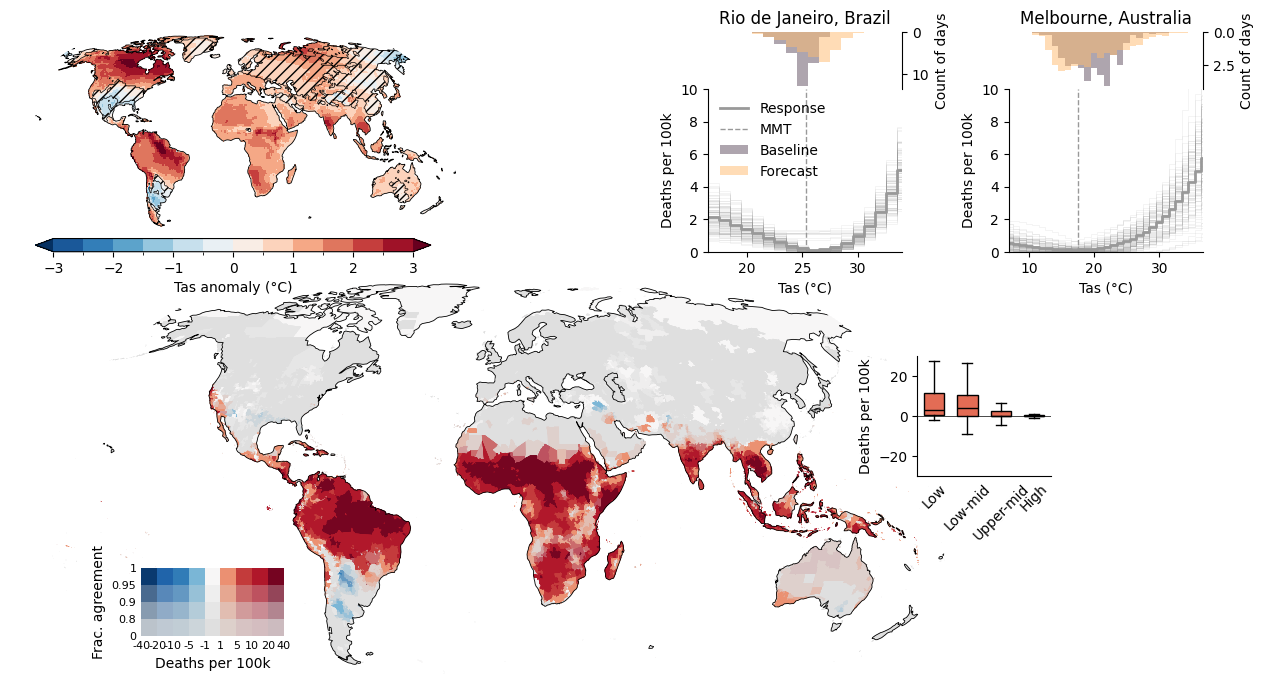

In [205]:
### Set Colors ###
COLORS = {"response": "#999999", "forecast": "#ffbb6f", "era5": "#5e4c5f"}

############ Set up the figure ##############
fig = plt.figure(figsize=(15, 7))
outer = fig.add_gridspec(
    2, 1, height_ratios=[0.55, 1], hspace=0.08,
    left=0.04, right=0.98, top=0.97, bottom=0.05,
) # 2 rows, 1 column for the outer grid. Bottom row is a big impact map

# Top: tas map on the left, the two diagrams sharing a narrower column
gs_top = outer[0].subgridspec(1, 2, width_ratios=[1.6, 0.9], wspace=0.05)
ax_tasmap = fig.add_subplot(gs_top[0], projection=ccrs.Robinson())
ax_tasmap.set_anchor("W")

# Gridspec for the two dose response curve panels. 
# Top row is histograms pointing down
# Bottom row is response curves
gs_diagrams = gs_top[1].subgridspec(
    2, 2, height_ratios=[.35, 1,], wspace=0.55, hspace=0.0,
)
ax_resp_at = fig.add_subplot(gs_diagrams[0, 0])
ax_resp_a = fig.add_subplot(gs_diagrams[1, 0], sharex=ax_resp_at)# bottom
ax_resp_a.set_anchor("S")
ax_resp_bt = fig.add_subplot(gs_diagrams[0, 1])
ax_resp_b = fig.add_subplot(gs_diagrams[1, 1], sharex=ax_resp_bt)# bottom


# Bottom: the impact map spans the full row height. The income chart only
# fills the upper part of its column.
gs_bottom = outer[1].subgridspec(
    1, 1, #height_ratios=[1, 0.9], #wspace=0.08, hspace=0.0,
    # 2, 2, width_ratios=[1, 0.1], height_ratios=[1, 0.9], wspace=0.08, hspace=0.0,
) # 2 rows, 1 column for the bottom outer row.

ax_impactmap = fig.add_subplot(gs_bottom[:], projection=ccrs.Robinson())# fig.add_subplot(gs_bottom[:, 0], projection=ccrs.Robinson())
ax_income = ax_impactmap.inset_axes([0.97, 0.50, 0.15, 0.30]) #[x, y, width, height]#fig.add_subplot(gs_bottom[0, 1])

# Legend drawn on the map, over the empty ocean at the lower left
cax = ax_impactmap.inset_axes([0.10, 0.10, 0.16, 0.17]) #[x, y, width, height]

# # ---- Panel labels ----
# for label, a in zip("ab", [ax_hotmap, ax_coldmap]):
#     a.text(
#         0.0,
#         1.0,
#         f"({label})",
#         transform=a.transAxes,
#         fontsize=12,
#         fontweight="bold",
#         va="bottom",
#         ha="left",
#     )
# for label, a in zip("cd", [ax_timeseries, ax_extra]):
#     a.text(
#         -0.3,
#         1.0,
#         f"({label})",
#         transform=a.transAxes,
#         fontsize=12,
#         fontweight="bold",
#         va="bottom",
#         ha="left",
#     )

###### Plotting below ##########
### Plot Forecast Mean ###
step = 0.5
vmax = np.ceil(float(abs(ens_mean).quantile(0.98)) / step) * step
levels = np.arange(-vmax, vmax + step, step)
# Plot ensemble mean
mesh = ens_mean.plot.pcolormesh(
    ax=ax_tasmap,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=levels,
    extend="both",
    add_colorbar=False,
)

ax_tasmap.coastlines(linewidth=0.6, color="k")
ax_tasmap.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_tasmap.spines["geo"].set_visible(False)
fig.colorbar(
    mesh,
    ax=ax_tasmap,
    orientation="horizontal",
    shrink=0.6,
    pad=0.03,
    aspect=30,
    fraction=0.06,
    label="Tas anomaly (°C)",
)
# Add Hatching: Sign greement across ensemble members
plotting_utils.add_polygons(ax_tasmap, mask, transform=ccrs.PlateCarree())

# Plot dose response curve panels
# ax_resp_a = fig.add_subplot(gs_top_row[1])
ax_resp_a, ax_hist_a = plot_region_panel_hanging(
    [ax_resp_a, ax_resp_at], clim_b1, beta_b1, COLORS, title=attrs_b1["region_title"],
    response_ylim=(0, 10),
)

# ax_resp_b = fig.add_subplot(gs_top_row[2])
ax_resp_b, ax_hist_b = plot_region_panel_hanging(
    [ax_resp_b, ax_resp_bt], clim_b2, beta_b2, COLORS, title=attrs_b2["region_title"],
    response_ylim=(0, 10), add_legend=False,
)


# Plot Impact Map
fill_colors = bivar_cmap(
    (norm_mean(gdf_hot["mean"].to_numpy()), norm_agr(gdf_hot["agr"].to_numpy()))
)
gdf_hot.plot(ax=ax_impactmap, color=fill_colors)
ax_impactmap.coastlines(linewidth=0.6, color="k")
ax_impactmap.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_impactmap.spines["geo"].set_visible(False)
ax_impactmap.set_axis_off()

# Plot bivar colormap
cax.imshow(
    legend_img,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=[0, len(mean_edges) - 1, 0, len(agreement_edges) - 1],
)
cax.set_xticks(range(len(mean_edges)), [f"{e:g}" for e in mean_edges])
cax.set_yticks(range(len(agreement_edges)), [f"{e:g}" for e in agreement_edges])
cax.tick_params(labelsize=8, length=0)
cax.spines[:].set_visible(False)
cax.set_xlabel("Deaths per 100k", fontsize=10)
cax.set_ylabel("Frac. agreement", fontsize=10)

# Plot income quartiles inset
# ======
quartile_labels = [
    "Low income",
    "Low-middle income",
    "Middle-high income",
    "High income",
]
cmap = plt.get_cmap("coolwarm")
colors = {"hotonly": mcolors.to_hex(cmap(0.85)), "coldonly": mcolors.to_hex(cmap(0.15))}

data_by_category, attrs_d = load_panel_d(FIG2D_PATH, quartile_labels)

ax = ax_income
positions = []
box_data = []
group_gap = 1
box_width = 0.6
n_quartiles = len(quartile_labels)

category = "hotonly"
i=0
# for i, category in enumerate(["hotonly", "coldonly"]):
for j, q_data in enumerate(data_by_category[category]):
    positions.append(i * (n_quartiles + group_gap) + j)
    box_data.append(q_data)

bp = ax.bxp(
    box_data,
    positions=positions,
    widths=box_width,
    patch_artist=True,
    medianprops={"color": "black"},
    showfliers=False,
)

for patch, color in zip(
    bp["boxes"],
    [colors[c] for c in ["hotonly", ] for _ in range(n_quartiles)],
):
    patch.set_facecolor(color)

# group_centers = [
#     i * (n_quartiles + group_gap) + (n_quartiles - 1) / 2 for i in range(2)
# ]

ax.set_ylim(-30, 30)
ax.set_xticks(positions)
ax.set_xticklabels(["Low", "Low-mid", "Upper-mid", "High"], fontsize=10, rotation=45)
ax.tick_params(axis="x", length=0)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_ylabel("Deaths per 100k")
ax.spines[
    [
        "right",
        "top",
    ]
].set_visible(False)


# sec = ax.secondary_xaxis(-0.45)
# sec.set_xticks(group_centers)
# sec.set_xticklabels(["Hot", "Cold"])
# sec.tick_params(length=0)


In [ ]:
if plotsave:
    fig.savefig(f"{config.version}_p01_method_results_withmelbourne_small.png", dpi=600, bbox_inches="tight")